In [1]:
from helpers import *

mpl.rcParams['font.size'] = 14

In [ ]:

eq_file_index = {
    "WF": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_WF/flow_properties.csv",'o', 'r'),
    "TWF": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TWF/flow_properties.csv",'p', 'orange'),
    "H": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_H/flow_properties.csv",'8', 'b'),
    "TM$_1$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_TM1/flow_properties.csv",'v', 'purple'),
    "M": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_M/flow_properties.csv",'d', 'y'),
    "sM$_1$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM1/flow_properties.csv",'s', 'g'),
    "sM$_2$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM2/flow_properties.csv",'^', 'b'),
    "sM$_{3,up}$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM3_up/flow_properties.csv",'>', 'brown'),
    "sM$_{3,low}$": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_sM3_low/flow_properties.csv",'<', 'brown'),
}

po_file_index = {
    "RPO1": "Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/timehistory/timehistory_s*.h5",
}

dns_file_index = {
    "DNS": ("Samples/Rrho40_Ra1e5_Pr7_tau0.01/Lx0.6_DNS/flowproperties/flowproperties_s*.h5",'-', 'gray'),
}

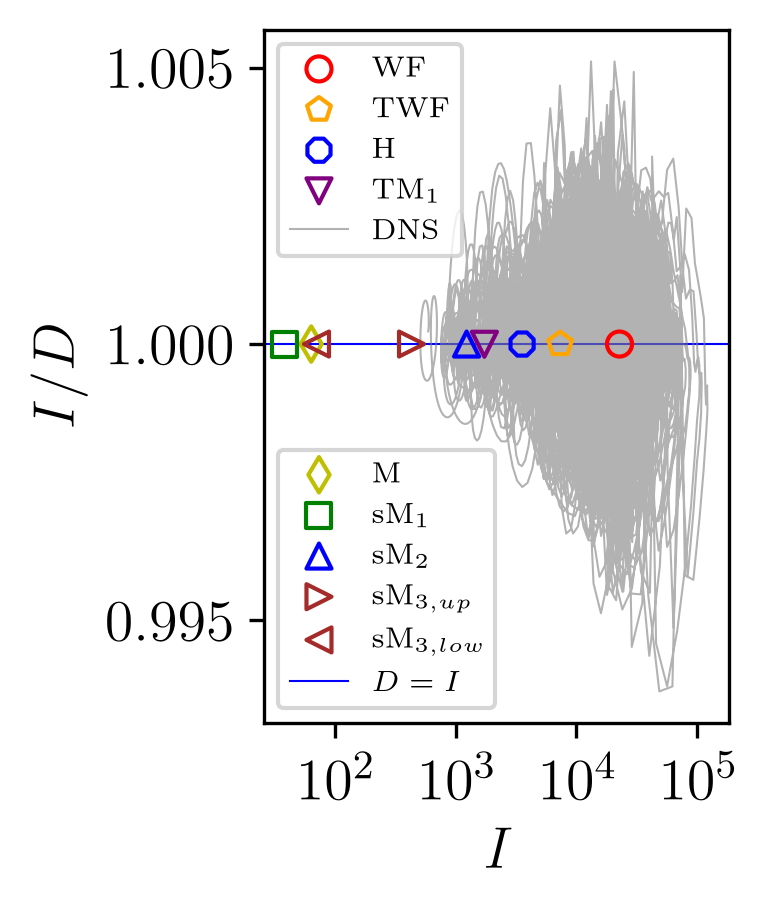

In [3]:
fig, ax = plt.subplots(figsize=(2,3), dpi=300)
line_eq = []
for eq_name, (file_path, marker, color) in eq_file_index.items():
    D, I = load_energy_eq(file_path)
    sc = ax.scatter(I,I/D, color=color, marker=marker, label=eq_name, facecolors="None", zorder=2)
    line_eq.append(sc)

line_dns = []
for dns_name, (file_pattern, linestyle, color) in dns_file_index.items():
    D, I = load_energy_dns(file_pattern)
    line, = ax.plot(I[:30000],I[:30000]/D[:30000], color=color, linestyle=linestyle, linewidth=0.5, label=dns_name, alpha=0.6, zorder=1)
    line_dns.append(line)

line_DI = ax.axline((0, 1), slope=0, linestyle='-', color='b', linewidth=0.5, label=r'$D=I$', zorder=0)

ax.set_xscale('log')
ax.set_xticks([1e2, 1e3, 1e4,1e5])
# ax.set_xticklabels(['$10^2$', '$10^3$', '$10^4$', '$10^5$'])
ax.set_xlabel(r'$I$')
ax.set_ylabel(r'$I/D$')


# Create the FIRST legend and assign it to a variable
first_legend = ax.legend(handles=line_eq[:4]+line_dns, loc='upper left', fontsize=7, frameon=True)
# Add the first legend manually to the axes
ax.add_artist(first_legend)
# Create the SECOND legend (this would normally delete legend #1)
ax.legend(handles=line_eq[4:]+[line_DI], loc='lower left', fontsize=7, frameon=True)

plt.savefig('Fig3a.png', format='png', dpi=600, bbox_inches='tight')
# plt.savefig('Fig3a.pdf', format='pdf', dpi=600, bbox_inches='tight')
plt.show()